In [5]:
#only motive is to tell about evaluation metrics here 
#its mse and r2 score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
#for any type of regression encoding the categorical feature is import and standardising numercial features also.


In [6]:
data = pd.read_csv(r'C:\Users\WINDOWS 11\Desktop\Jupyter Notebook\other stuff\ML\New folder\datasets\car_detail.csv')
data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB


In [8]:
data.describe(include = 'number')

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [9]:
data.describe(include = 'str')

,name,fuel,seller_type,transmission,owner
count,4340,4340,4340,4340,4340
unique,1491,5,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,69,2153,3244,3892,2832


In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
#scale numerical values
columns = ['km_driven']
for col in columns:
    data[col] = scaler.fit_transform(data[[col]])
data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,0.081139,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,-0.347689,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,0.724381,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,-0.433455,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,1.603479,Diesel,Individual,Manual,Second Owner


In [11]:
#now convert categorical values into numerical for seller type ,transmission,owner and fuel
data = pd.get_dummies(data,columns = ['seller_type' ,'transmission','owner' ,'fuel'] ,drop_first = True,dtype = int)
data.head()

,name,year,selling_price,km_driven,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol
0,Maruti 800 AC,2007,60000,0.081139,1,0,1,0,0,0,0,0,0,0,1
1,Maruti Wagon R LXI Minor,2007,135000,-0.347689,1,0,1,0,0,0,0,0,0,0,1
2,Hyundai Verna 1.6 SX,2012,600000,0.724381,1,0,1,0,0,0,0,1,0,0,0
3,Datsun RediGO T Option,2017,250000,-0.433455,1,0,1,0,0,0,0,0,0,0,1
4,Honda Amaze VX i-DTEC,2014,450000,1.603479,1,0,1,0,1,0,0,1,0,0,0


In [12]:
#names are lot ,so drop them 
data.drop(columns = ['name'],inplace = True)
data.head()

,year,selling_price,km_driven,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol
0,2007,60000,0.081139,1,0,1,0,0,0,0,0,0,0,1
1,2007,135000,-0.347689,1,0,1,0,0,0,0,0,0,0,1
2,2012,600000,0.724381,1,0,1,0,0,0,0,1,0,0,0
3,2017,250000,-0.433455,1,0,1,0,0,0,0,0,0,0,1
4,2014,450000,1.603479,1,0,1,0,1,0,0,1,0,0,0


In [16]:
#create a new column named age so that it accounts sutaibly for the year
data.insert(0,'Age',data['year'].max()-data['year']+1)
data.drop(columns = ['year'],inplace = True)
data.head()

ValueError: cannot insert Age, already exists

In [17]:
X = data.drop('selling_price',axis = 1)
y = data['selling_price']
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)
X_train.shape
#X_test.shape

(3472, 14)

In [18]:
data.columns = data.columns.str.strip()

ValueError: Could not interpret value `seller_type_individual` for `hue`. An entry with this name does not appear in `data`.

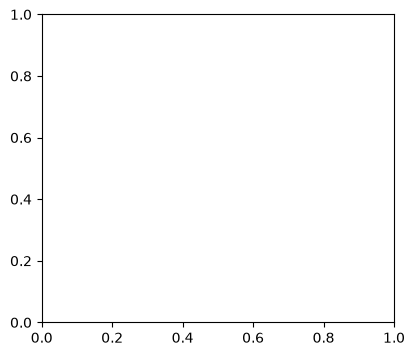

In [19]:
#scatter plot
plt.figure(figsize = (10,4))

plt.subplot(121)
sns.scatterplot(data,x = 'Age',y = 'selling_price',hue = 'seller_type_individual',pallete = 'Set1')
plt.title('Scatter plot of Selling Price vs Age')

plt.subplot(122)
sns.scatterplot(data,x = 'km_driven',y = 'selling_price',hue = 'seller_type_individual',pallete = 'Set1')
plt.title('Scatter plot of Selling Price vs km_driven')


In [20]:
#now builing the Linear model first
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
model = LinearRegression()
model.fit(X_train,y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[ -17882.22, 17882.22, -46962.18,...,-640119.34, 53484.37, -20697.35]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['Age','year','km_driven',...,'fuel_Electric','fuel_LPG','fuel_Petrol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.462e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [21]:
model.coef_

array([-1.78822211e+04,  1.78822211e+04, -4.69621846e+04, -6.98192679e+04,
        1.69804232e+05, -8.91338059e+05,  6.13220830e+02, -3.60457137e+04,
        1.30679820e+05, -2.70647518e+04,  2.79850785e+05, -6.40119340e+05,
        5.34843662e+04, -2.06973547e+04])

In [22]:
#after fitting ,the coefficients must have got fixed
#now we want to see the cf so
pd.DataFrame(data = np.append(model.intercept_,model.coef_),
             index = ['Intercept']+[col + ' Coeff' for col in X.columns],columns = ['VALUE']).sort_values('VALUE',ascending = False)

,VALUE
fuel_Diesel Coeff,2.798508e+05
seller_type_Trustmark Dealer Coeff,1.698042e+05
owner_Test Drive Car Coeff,1.306798e+05
fuel_LPG Coeff,5.348437e+04
year Coeff,1.788222e+04
owner_Fourth & Above Owner Coeff,6.132208e+02
Age Coeff,-1.788222e+04
fuel_Petrol Coeff,-2.069735e+04
owner_Third Owner Coeff,-2.706475e+04
owner_Second Owner Coeff,-3.604571e+04


In [23]:
#model evaluation function 
from sklearn import metrics
def model_evaluation(model,X_test,y_test):
    pred = model.predict(X_test)
    r2 = r2_score(y_test,pred)
    MSE = metrics.mean_squared_error(y_test,pred)
    MAE = metrics.mean_absolute_error(y_test,pred)
    RMSE = np.sqrt(MSE)
    df = pd.DataFrame(data = [r2,MSE,MAE,RMSE],index = ['R2','MSE','MAE','RMSE'],columns = ['VALUES'])
    return df

In [24]:
report = model_evaluation(model,X_test,y_test)
report

,VALUES
R2,4.031304e-01
MSE,1.821469e+11
MAE,2.217064e+05
RMSE,4.267867e+05


In [25]:
#NOW CREATING POLYNOMIAL REGRESSION
#IMP - WE MAKE THE DATA TO BE POLYNOMIAL ITSELF BY CREATING MORE FEATURES LIKE COL (i) * COL(j) FOR ALL i,j <=no_of intial features
#note: for only deg = 2 we have col(i)*col(j) otherwise it would have been col(i)col(j)col(k) for deg = 3 and so on
from sklearn.preprocessing import PolynomialFeatures
poly_feature = PolynomialFeatures(degree = 2 ,include_bias =False)
X_poly = poly_feature.fit_transform(X)



In [26]:
X_poly_train,X_poly_test,y_train,y_test = train_test_split(X_poly,y,test_size = 0.2,random_state = 42)
X_poly_train.shape

(3472, 119)

In [28]:
poly_feature_names = poly_feature.get_feature_names_out(X.columns)
len(poly_feature_names)

119

In [29]:
#NOW TRAIN THE MODEL WITH POLYNOMIAL DATASET USING SIMPLE MULTIPLE REGRESSION
from sklearn.linear_model import LinearRegression
poly_model = LinearRegression()
poly_model.fit(X_poly_train,y_train)
pred = poly_model.predict(X_poly_test)
model_evaluation(poly_model,X_poly_test,y_test)

,VALUES
R2,4.675340e-01
MSE,1.624928e+11
MAE,1.954188e+05
RMSE,4.031040e+05


In [ ]:
#we can see that mse has been reduced so its fits well